# Experiment 2 — Pretrained PointPillars + YOLOv8

Use the same shared fusion implementation as Experiment 1. The LiDAR detector and its preprocessing are the experiment-specific components.

## Data and Model Setup

Inspect the Waymo camera and LiDAR data, verify frame synchronization and calibration, and initialize the pretrained PointPillars detector. These checks establish that the data pipeline and model are ready for the fusion experiment.

In [ ]:
# Loads the camera and LiDAR parquet files and inspects their schemas and sample rows.
from pathlib import Path
import inspect
import pandas as pd

from src.data.waymo_loader import (
    load_camera_image,
    load_top_lidar_points,
)

segment_id = "10017090168044687777_6380_000_6400_000"
training_root = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/training"
)

# Inspect the source parquet schemas first.
camera_path = training_root / "camera_image" / f"{segment_id}.parquet"
lidar_path = training_root / "lidar" / f"training_lidar_{segment_id}.parquet"

camera_df = pd.read_parquet(camera_path)
lidar_df = pd.read_parquet(lidar_path)

print("\nCamera parquet shape:", camera_df.shape)
print("Camera columns:", camera_df.columns.tolist())
print("\nLiDAR parquet shape:", lidar_df.shape)
print("LiDAR columns:", lidar_df.columns.tolist())
print("\nLiDAR sample:")
print(lidar_df.head(2).to_string())


Camera parquet shape: (990, 15)
Camera columns: ['key.segment_context_name', 'key.frame_timestamp_micros', 'key.camera_name', '[CameraImageComponent].image', '[CameraImageComponent].pose.transform', '[CameraImageComponent].velocity.linear_velocity.x', '[CameraImageComponent].velocity.linear_velocity.y', '[CameraImageComponent].velocity.linear_velocity.z', '[CameraImageComponent].velocity.angular_velocity.x', '[CameraImageComponent].velocity.angular_velocity.y', '[CameraImageComponent].velocity.angular_velocity.z', '[CameraImageComponent].pose_timestamp', '[CameraImageComponent].rolling_shutter_params.shutter', '[CameraImageComponent].rolling_shutter_params.camera_trigger_time', '[CameraImageComponent].rolling_shutter_params.camera_readout_done_time']

LiDAR parquet shape: (990, 7)
LiDAR columns: ['key.segment_context_name', 'key.frame_timestamp_micros', 'key.laser_name', '[LiDARComponent].range_image_return1.values', '[LiDARComponent].range_image_return1.shape', '[LiDARComponent].rang

In [ ]:
# Checks timestamp overlap between front-camera and LiDAR data and identifies the LiDAR sensors associated with a shared timestamp.
import pyarrow.parquet as pq

# Read only the columns needed to identify a shared frame.
camera_table = pq.read_table(
    camera_path,
    columns=["key.frame_timestamp_micros", "key.camera_name"]
)
lidar_table = pq.read_table(
    lidar_path,
    columns=["key.frame_timestamp_micros", "key.laser_name"]
)

camera_df = camera_table.to_pandas()
lidar_df = lidar_table.to_pandas()

front_camera = camera_df[camera_df["key.camera_name"] == 1]
camera_timestamps = set(front_camera["key.frame_timestamp_micros"])
lidar_timestamps = set(lidar_df["key.frame_timestamp_micros"])
shared_timestamps = sorted(camera_timestamps & lidar_timestamps)

print("Front camera frames:", len(camera_timestamps))
print("LiDAR timestamps:", len(lidar_timestamps))
print("Shared timestamps:", len(shared_timestamps))

if shared_timestamps:
    timestamp = int(shared_timestamps[0])
    sensors = lidar_df.loc[
        lidar_df["key.frame_timestamp_micros"] == timestamp,
        "key.laser_name"
    ].tolist()
    print("Selected timestamp:", timestamp)
    print("LiDAR sensor IDs:", sensors)

Front camera frames: 198
LiDAR timestamps: 198
Shared timestamps: 198
Selected timestamp: 1550083467346370
LiDAR sensor IDs: [1, 2, 3, 4, 5]


Return type: <class 'tuple'>
Tuple length: 2

Item 0:
  Type: <class 'PIL.Image.Image'>
  Shape: None
  Dtype: None

Item 1:
  Type: <class 'pandas.core.series.Series'>
  Shape: (15,)
  Dtype: object
Image size: (1920, 1280)
Image mode: RGB
Camera metadata fields: 15


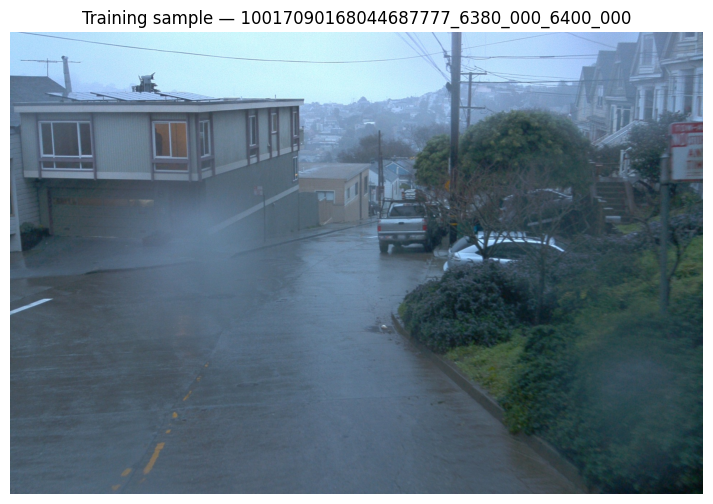

In [ ]:
# Loads and displays a camera image and inspects its metadata and return type.
from src.data.waymo_loader import load_camera_image
import matplotlib.pyplot as plt
import numpy as np

data_root = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")

image = load_camera_image(
    segment_id,
    camera_name=1,
    split="training",
    data_root=data_root,
)

print("Return type:", type(image))

if isinstance(image, tuple):
    print("Tuple length:", len(image))
    for i, item in enumerate(image):
        print(f"\nItem {i}:")
        print("  Type:", type(item))
        print("  Shape:", getattr(item, "shape", None))
        print("  Dtype:", getattr(item, "dtype", None))
        if isinstance(item, (str, int, float, type(None))):
            print("  Value:", item)
elif isinstance(image, np.ndarray):
    print("Shape:", image.shape)
    print("Dtype:", image.dtype)
else:
    print("Value type details:", repr(image)[:500])

camera_image, camera_metadata = image

print("Image size:", camera_image.size)
print("Image mode:", camera_image.mode)
print("Camera metadata fields:", len(camera_metadata))

plt.figure(figsize=(12, 6))
plt.imshow(camera_image)
plt.axis("off")
plt.title(f"Training sample — {segment_id}")
plt.show()



In [ ]:
# Loads the converted fusion context, camera calibration and synchronized frames, then checks timestamps, image dimensions and point-cloud shape.

import sys
from pathlib import Path

if "/content" not in sys.path:
    sys.path.insert(0, "/content")

from src.data.waymo_fusion_data import (
    ensure_converted_context,
    available_frame_indices,
    load_camera_calibration,
    load_fusion_frame,
)

# Restore the existing converted sample if needed
context_dir = ensure_converted_context()

# Check calibration and available synchronized frames
calibration = load_camera_calibration(context_dir)
frame_indices = available_frame_indices(context_dir)

# Load one frame
frame_idx = frame_indices[0]
frame = load_fusion_frame(context_dir, frame_idx)

print("\n--- Data pipeline check ---")
print("Context:", context_dir)
print("Calibration keys:", list(calibration.keys()))
print("Frame index:", frame_idx)
print("Image size:", frame["image"].size)
print("LiDAR points:", frame["points"].shape)
print("Camera timestamp:", frame["camera_timestamp"])
print("LiDAR timestamps:", frame["lidar1_timestamp"], frame["lidar2_timestamp"])


Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

--- Data pipeline check ---
Context: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Calibration keys: ['camera_name', 'context', 'intrinsic', 'extrinsic', 'width', 'height', 'rolling_shutter_direction']
Frame index: 0
Image size: (1920, 1280)
LiDAR points: (165170, 5)
Camera timestamp: 1550083467346370
LiDAR timestamps: 1550083467346370 1550083467346370


In [ ]:
# Reloads the pretrained PointPillars module and loads the model, runtime and configuration.
import importlib
import src.models.pointpillars_pretrained as pretrained

importlib.reload(pretrained)

model, runtime, cfg = pretrained.load_pretrained_pointpillars()

Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']


## Single-Frame Detection and Projection Diagnostics

Run the pretrained LiDAR detector on a representative frame and compare its projected 3D boxes with the YOLOv8 camera detections. Investigate projection failures and use geometric checks to distinguish invalid projections from objects that genuinely fall outside the camera's field of view.

In [ ]:
# Runs pretrained PointPillars on one frame and prints detection classes, scores, 3D boxes and projected 2D boxes.
import numpy as np
from src.data.waymo_fusion_data import (
    ensure_converted_context, load_camera_calibration,
    load_fusion_frame, available_frame_indices,
)
from src.models.pointpillars_pretrained import (
    load_pretrained_pointpillars, predict_pretrained_lidar,
)
from src.fusion.projection import load_camera_geometry, project_lidar_box

context_dir = ensure_converted_context()
frame_idx = available_frame_indices(context_dir)[0]
frame = load_fusion_frame(context_dir, frame_idx)
geometry = load_camera_geometry(load_camera_calibration(context_dir))

model, runtime, cfg = load_pretrained_pointpillars()
points = np.asarray(frame["points"], dtype=np.float32)
detections = predict_pretrained_lidar(model, runtime, points, cfg)

print("Frame:", frame_idx)
print("Raw points:", points.shape)
print("Pretrained detections:", len(detections))

for i, det in enumerate(detections[:10]):
    box = np.asarray(det["box"], dtype=float)
    projected = project_lidar_box(
        box, points,
        geometry["T_camera_vehicle"], geometry["K"], geometry["dist"],
        geometry["image_width"], geometry["image_height"],
    )
    print(
        f"{i}: class={runtime['classes'][det['label']]}, "
        f"score={det['score']:.3f}, "
        f"box={np.round(box, 2).tolist()}, "
        f"projected={np.round(projected, 1).tolist() if projected is not None else None}"
    )

Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']
Frame: 0
Raw points: (165170, 5)
Pretrained detections: 3
0: class=vehicle, score=0.996, box=[21.06, -4.66, 2.39, 4.58, 2.2, 0.74, -1.71], projected=[1188.4, 556.1, 1713.2, 647.7]
1: class=vehicle, score=0.994, box=[31.92, -2.38, 2.84, 6.33, 2.63, 0.98, -0.14], projected=[992.5, 532.6, 1201.1, 612.9]
2: class=vehicle, score=0.987, box=[19.13, 12.6, 0.54, 5.4, 2.3, 1.24, -1.72], projected=None


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


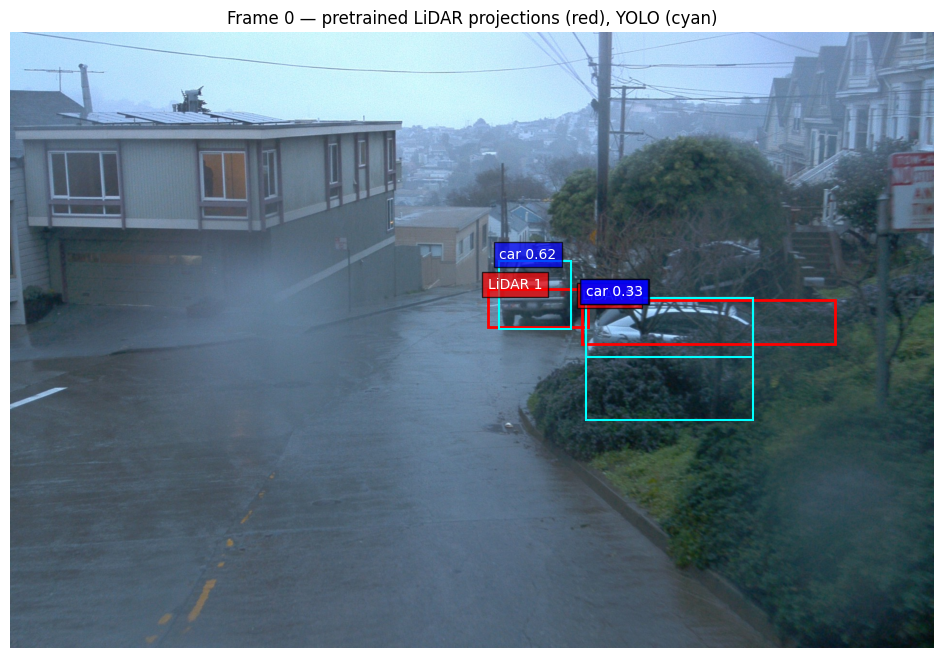

YOLO detections: 3


In [ ]:
# Draws projected LiDAR boxes and YOLO detections on the same camera image.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from src.models.camera_detector import load_camera_detector, predict_camera

camera_model = load_camera_detector()
camera_output = predict_camera(camera_model, frame["image"], confidence=0.25)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(frame["image"])

for i, det in enumerate(detections):
    box = project_lidar_box(
        det["box"], points,
        geometry["T_camera_vehicle"], geometry["K"], geometry["dist"],
        geometry["image_width"], geometry["image_height"],
    )
    if box is None:
        continue
    x1, y1, x2, y2 = box
    ax.add_patch(Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="red", linewidth=2,
    ))
    ax.text(x1, y1, f"LiDAR {i}", color="white",
            bbox=dict(facecolor="red", alpha=0.7))

names = camera_output["names"]
for box, score, label in zip(
    camera_output["boxes"], camera_output["scores"], camera_output["labels"]
):
    x1, y1, x2, y2 = box
    name = names[int(label)]
    ax.add_patch(Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="cyan", linewidth=1.5,
    ))
    ax.text(x1, max(0, y1-5), f"{name} {score:.2f}", color="white",
            bbox=dict(facecolor="blue", alpha=0.7))

ax.set_title("Frame 0 — pretrained LiDAR projections (red), YOLO (cyan)")
ax.axis("off")
plt.show()

print("YOLO detections:", len(camera_output["boxes"]))

In [ ]:
# Calculates IoU between projected LiDAR boxes and YOLO vehicle detections.
from src.fusion.matching import box_iou

for i, det in enumerate(detections):
    lidar_box = project_lidar_box(
        det["box"], points,
        geometry["T_camera_vehicle"], geometry["K"], geometry["dist"],
        geometry["image_width"], geometry["image_height"],
    )
    if lidar_box is None:
        print(f"LiDAR {i}: not projected")
        continue

    overlaps = []
    for j, (cam_box, score, label) in enumerate(zip(
        camera_output["boxes"],
        camera_output["scores"],
        camera_output["labels"],
    )):
        name = camera_output["names"][int(label)]
        if name in {"car", "truck", "bus"}:
            overlaps.append((j, name, float(score),
                             float(box_iou(lidar_box, cam_box))))

    print(f"LiDAR {i}: best vehicle overlaps = {sorted(overlaps, key=lambda x: x[3], reverse=True)}")

LiDAR 0: best vehicle overlaps = [(2, 'car', 0.3264853060245514, 0.5430978536605835), (1, 'car', 0.45230862498283386, 0.30464980006217957), (0, 'car', 0.6200947165489197, 0.0)]
LiDAR 1: best vehicle overlaps = [(0, 'car', 0.6200947165489197, 0.4614289700984955), (2, 'car', 0.3264853060245514, 0.005881150718778372), (1, 'car', 0.45230862498283386, 0.0023751307744532824)]
LiDAR 2: not projected


In [ ]:
# Reloads run_experiment_2 and calls exp2.main(camera_model).
import importlib
import experiments.run_experiment_2 as exp2

importlib.reload(exp2)

camera_model = exp2.load_camera_detector()
summaries = exp2.main(camera_model)

Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']

Experiment 2 initialized
Results directory: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results
LiDAR class names: ['pedestrian', 'cyclist', 'vehicle']
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Frame 0: 165,170 LiDAR points
Visualization: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results/frame_000.jpg
LiDAR detections: 3
Camera candidates: 3
Projected LiDAR boxes: 2
Matched pairs: 2
Saved results: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results/detections.csv
Frame processing time: 2.15 s

Experiment 2 summary
Frame 0: LiDAR=3, camera=3, pr

Inspect results for this one frame:

CSV columns: ['frame_idx', 'lidar_class', 'lidar_score', 'x', 'y', 'z', 'dx', 'dy', 'dz', 'heading', 'projected_camera_box', 'matched_camera_labels', 'matched_camera_score', 'match_iou', 'matched']
Number of rows: 3


,frame_idx,lidar_class,lidar_score,x,y,z,dx,dy,dz,heading,projected_camera_box,matched_camera_labels,matched_camera_score,match_iou,matched
0,0,vehicle,0.995896,21.057755,-4.656215,2.389218,4.583426,2.198709,0.744294,-1.711622,"[1188.3785363110455, 556.143304327291, 1713.18...",car,0.326485,0.543098,True
1,0,vehicle,0.994255,31.916040,-2.384731,2.837064,6.328757,2.625450,0.979169,-0.141177,"[992.4858804930336, 532.6219082111862, 1201.12...",car,0.620095,0.461429,True
2,0,vehicle,0.986894,19.126093,12.595178,0.542824,5.399682,2.304419,1.244102,-1.718556,NaN,NaN,NaN,NaN,False


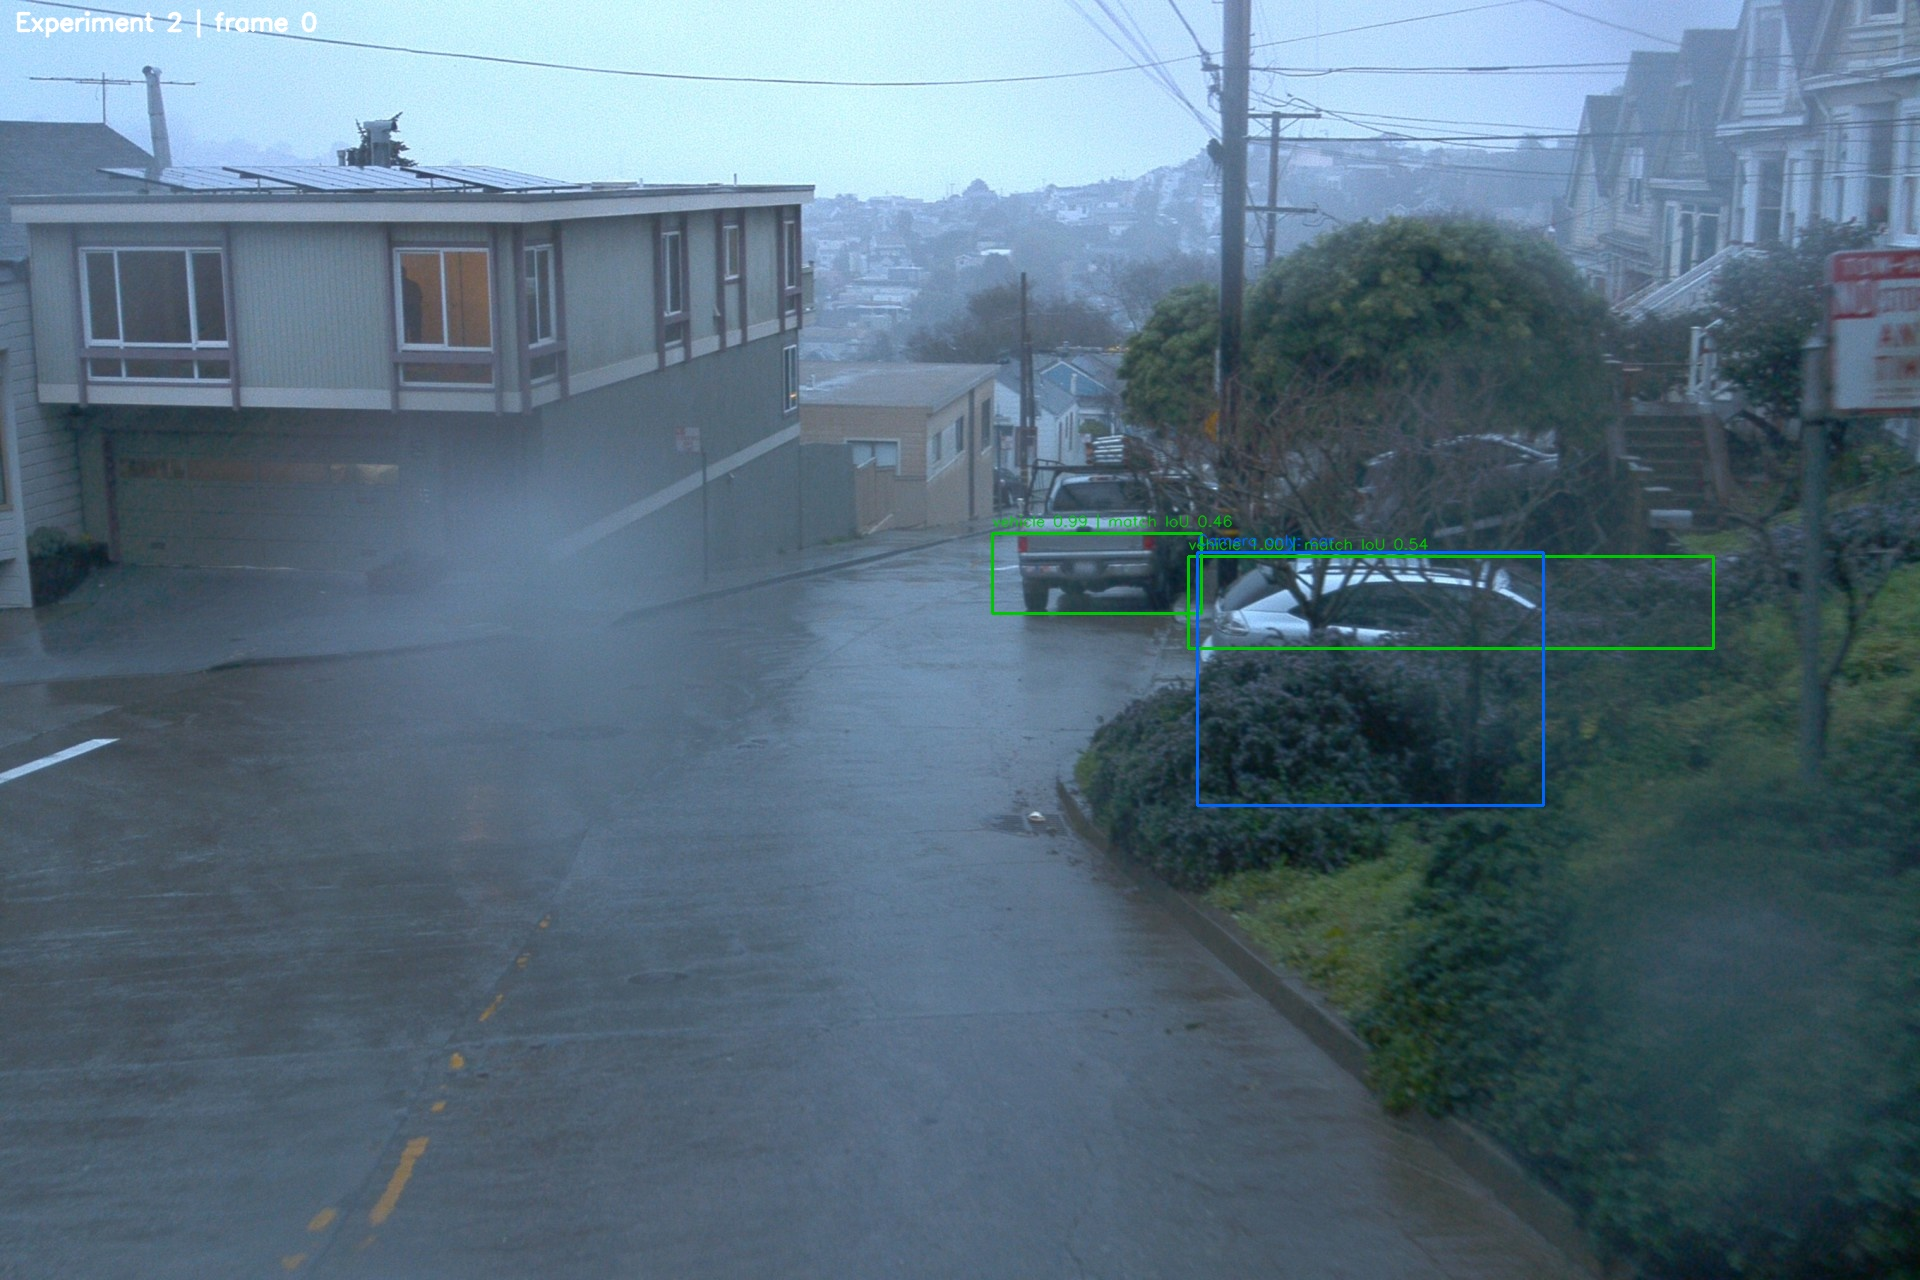

In [ ]:
# Introduces inspection of the results from a single frame.
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

results_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results"
)

csv_path = results_dir / "detections.csv"
image_path = results_dir / "frame_000.jpg"

# Inspect recorded detections and associations
df = pd.read_csv(csv_path)
print("CSV columns:", df.columns.tolist())
print("Number of rows:", len(df))
display(df)

# Inspect the saved visualization
if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Visualization not found:", image_path)

In [ ]:
# Loads the generated CSV, displays its rows and shows the saved frame visualization if available.
import numpy as np
from src.data.waymo_fusion_data import (
    ensure_converted_context, load_camera_calibration,
    available_frame_indices, load_fusion_frame
)
from src.fusion.projection import load_camera_geometry, project_lidar_box
from src.models.pointpillars_pretrained import (
    load_pretrained_pointpillars, predict_pretrained_lidar
)

context_dir = ensure_converted_context()
calibration = load_camera_calibration(context_dir)
geometry = load_camera_geometry(calibration)
frame_idx = available_frame_indices(context_dir)[0]
frame = load_fusion_frame(context_dir, frame_idx)
points = np.asarray(frame["points"])
device_model, runtime, cfg = load_pretrained_pointpillars()
detections = predict_pretrained_lidar(device_model, runtime, points, cfg)

for i, det in enumerate(detections):
    x, y, z, sx, sy, dz, heading = det["box"]
    c, s = np.cos(heading), np.sin(heading)
    dxp, dyp = points[:, 0] - x, points[:, 1] - y
    lx = dxp * c + dyp * s
    ly = -dxp * s + dyp * c
    finite = np.isfinite(points[:, :3]).all(axis=1)
    support = finite & (np.abs(lx) <= sx / 2) & (np.abs(ly) <= sy / 2)

    projected = project_lidar_box(
        det["box"], points,
        geometry["T_camera_vehicle"], geometry["K"],
        geometry["dist"], calibration["width"], calibration["height"]
    )
    print(
        f"Detection {i}: class={det['label']}, score={det['score']:.3f}, "
        f"BEV support={support.sum()}, projected={projected}"
    )

Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']
Detection 0: class=2, score=0.996, BEV support=359, projected=[1188.3785363110455, 556.143304327291, 1713.1848746425594, 647.657815453856]
Detection 1: class=2, score=0.994, BEV support=309, projected=[992.4858804930336, 532.6219082111862, 1201.124577908784, 612.9497014518075]
Detection 2: class=2, score=0.987, BEV support=311, projected=None


In [ ]:
# Re-runs the pretrained detector and calculates bird’s-eye-view point support for each 3D box, alongside its projection result.
import numpy as np

i = 2
x, y, z, sx, sy, dz, heading = map(float, detections[i]["box"])

c, s = np.cos(heading), np.sin(heading)
local_xy = np.array([
    [-sx/2, -sy/2], [sx/2, -sy/2],
    [sx/2, sy/2], [-sx/2, sy/2]
])
xy = local_xy @ np.array([[c, -s], [s, c]]).T + [x, y]

corners = np.vstack([
    np.column_stack([xy, np.full(4, z - dz/2)]),
    np.column_stack([xy, np.full(4, z + dz/2)])
])
corners_h = np.column_stack([corners, np.ones(8)])

T = geometry["T_camera_vehicle"]
cam = (T @ corners_h.T).T[:, :3]
cv = np.column_stack([-cam[:, 1], -cam[:, 2], cam[:, 0]])

print("3D box:", detections[i]["box"])
print("Camera-aligned coordinates (first 3 corners):\n", cam[:3])
print("Optical coordinates (x, y, depth):\n", cv)
print("Depth range:", cv[:, 2].min(), "to", cv[:, 2].max())
print("Projected box:", project_lidar_box(
    detections[i]["box"], points,
    T, geometry["K"], geometry["dist"],
    calibration["width"], calibration["height"]
))

3D box: [19.1260929107666, 12.59517765045166, 0.5428237915039062, 5.39968204498291, 2.3044192790985107, 1.2441024780273438, -1.7185556888580322]
Camera-aligned coordinates (first 3 corners):
 [[     16.807      15.549     -1.8213]
 [     16.029      10.206     -1.9214]
 [      18.31      9.8744     -1.9143]]
Optical coordinates (x, y, depth):
 [[    -15.549      1.8213      16.807]
 [    -10.206      1.9214      16.029]
 [    -9.8744      1.9143       18.31]
 [    -15.217      1.8143      19.087]
 [    -15.527     0.57742        16.8]
 [    -10.184     0.67748      16.022]
 [    -9.8521     0.67043      18.302]
 [    -15.195     0.57037       19.08]]
Depth range: 16.02205802156794 to 19.087114457258743
Projected box: None


In [ ]:
# Constructs the eight corners of detection 2, transforms them into camera coordinates and calculates their depths.
K = geometry["K"]
W, H = calibration["width"], calibration["height"]
fx, fy = K[0, 0], K[1, 1]
cx, cy = K[0, 2], K[1, 2]

near = 0.1
planes = {
    "near": lambda p: p[2] - near,
    "left": lambda p: fx * p[0] + cx * p[2],
    "right": lambda p: -fx * p[0] + (W - cx) * p[2],
    "top": lambda p: fy * p[1] + cy * p[2],
    "bottom": lambda p: -fy * p[1] + (H - cy) * p[2],
}

print("Image size:", W, "x", H)
for name, fn in planes.items():
    distances = np.array([fn(p) for p in cv])
    print(
        f"{name:>6}: min={distances.min():.2f}, "
        f"max={distances.max():.2f}, "
        f"corners inside={np.sum(distances >= 0)}/8"
    )

Image size: 1920 x 1280
  near: min=15.92, max=18.99, corners inside=8/8
  left: min=-16017.78, max=-2860.16, corners inside=0/8
 right: min=36478.23, max=49809.32, corners inside=8/8
   top: min=11562.74, max=15849.10, corners inside=8/8
bottom: min=6388.15, max=11139.75, corners inside=8/8


Detection 2 is outside the camera's field of view on the left. All eight corners fail the left-frustum test, while all eight satisfy the other four tests. Its depth is positive, so the box is in front of the camera, but it is too far to the left to appear in the image.

## Preliminary Run and Output Inspection

Inspect the detections, projected bounding boxes and associations saved by the preliminary experiment run. Use the visualization and CSV output to verify that the pipeline produces interpretable results.

Calculate initial detection, projection and association statistics from the saved results. These metrics provide a preliminary check of the pipeline before running the experiment over the full selected sequence.

In [ ]:
# Calculates detection counts, projection rate, association rate and mean matched IoU from the CSV.
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results"
)
df = pd.read_csv(results_dir / "detections.csv")

total = len(df)
projected = df["projected_camera_box"].notna().sum()
matched = df["matched"].astype(str).str.lower().eq("true").sum()
ious = pd.to_numeric(df.loc[df["matched"].astype(str).str.lower().eq("true"), "match_iou"], errors="coerce").dropna()

print(f"LiDAR detections: {total}")
print(f"Projected detections: {projected}")
print(f"Matched detections: {matched}")
print(f"Projection rate: {projected / total:.1%}" if total else "Projection rate: N/A")
print(f"Association rate among projected: {matched / projected:.1%}" if projected else "Association rate: N/A")
print(f"Mean matched IoU: {ious.mean():.3f}" if len(ious) else "Mean matched IoU: N/A")

LiDAR detections: 3
Projected detections: 2
Matched detections: 2
Projection rate: 66.7%
Association rate among projected: 100.0%
Mean matched IoU: 0.502


In [ ]:
# Backs up detections.csv and deletes the original CSV in preparation for a fresh run.
from pathlib import Path
import shutil

results_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results"
)

csv_path = results_dir / "detections.csv"
backup_path = results_dir / "detections_frame0_backup.csv"

if csv_path.exists():
    shutil.copy2(csv_path, backup_path)
    csv_path.unlink()
    print(f"Previous CSV backed up to: {backup_path}")
    print("Old CSV cleared for the full run.")
else:
    print("No previous CSV found; ready for the full run.")

Previous CSV backed up to: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results/detections_frame0_backup.csv
Old CSV cleared for the full run.


## Full Experiment Execution

Prepare a clean output file and execute Experiment 2 over the configured set of frames. Preserve the previous results before clearing the CSV, so that the preliminary run remains recoverable.

We increase the batch so we process all the frames:

In [ ]:
# Reloads the experiment module, loads the camera detector and runs exp2.main(camera_model) again.
import importlib
import experiments.run_experiment_2 as exp2

importlib.reload(exp2)

camera_model = exp2.load_camera_detector()
summaries = exp2.main(camera_model)

Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']

Experiment 2 initialized
Results directory: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results
LiDAR class names: ['pedestrian', 'cyclist', 'vehicle']
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Frame 0: 165,170 LiDAR points
Visualization: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results/frame_000.jpg
LiDAR detections: 3
Camera candidates: 3
Projected LiDAR boxes: 2
Matched pairs: 2
Saved results: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_2_results/detections.csv
Frame processing time: 1.70 s

Frame 1: 164,867 LiDAR points
Visualization: /conte

## Results and Analysis

Analyze the outputs generated by the full experiment. Evaluate detection projection and camera–LiDAR association quantitatively, examine variation across frames, and inspect visual examples to understand successful matches and failure cases.

In [ ]:
# Calculates overall metrics and per-frame statistics, then displays frames with the fewest and most matches.
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results"
)
df = pd.read_csv(results_dir / "detections.csv")

# Interpret saved fields
df["matched"] = df["matched"].astype(str).str.lower().eq("true")
df["projected"] = df["projected_camera_box"].notna()
df["match_iou"] = pd.to_numeric(df["match_iou"], errors="coerce")

per_frame = df.groupby("frame_idx").agg(
    lidar_detections=("lidar_class", "size"),
    projected_detections=("projected", "sum"),
    matched_detections=("matched", "sum"),
    mean_matched_iou=("match_iou", "mean"),
)

total_lidar = len(df)
total_projected = int(df["projected"].sum())
total_matched = int(df["matched"].sum())
matched_ious = df.loc[df["matched"], "match_iou"].dropna()

print("=== OVERALL RESULTS ===")
print(f"Frames in CSV: {df['frame_idx'].nunique()}")
print(f"LiDAR detections: {total_lidar}")
print(f"Projected detections: {total_projected}")
print(f"Matched detections: {total_matched}")
print(f"Projection rate: {total_projected / total_lidar:.1%}" if total_lidar else "Projection rate: N/A")
print(f"Match rate among projected: {total_matched / total_projected:.1%}" if total_projected else "Match rate: N/A")
print(f"Mean matched IoU: {matched_ious.mean():.3f}" if len(matched_ious) else "Mean matched IoU: N/A")
print(f"Median matched IoU: {matched_ious.median():.3f}" if len(matched_ious) else "Median matched IoU: N/A")

print("\n=== PER-FRAME SUMMARY ===")
display(per_frame.describe().round(3))

print("\n=== FRAMES WITH FEWEST MATCHES ===")
display(per_frame.sort_values(["matched_detections", "mean_matched_iou"]).head(10).round(3))

print("\n=== FRAMES WITH MOST MATCHES ===")
display(per_frame.sort_values(["matched_detections", "mean_matched_iou"], ascending=False).head(10).round(3))

=== OVERALL RESULTS ===
Frames in CSV: 198
LiDAR detections: 1095
Projected detections: 742
Matched detections: 545
Projection rate: 67.8%
Match rate among projected: 73.5%
Mean matched IoU: 0.565
Median matched IoU: 0.543

=== PER-FRAME SUMMARY ===


,lidar_detections,projected_detections,matched_detections,mean_matched_iou
count,198.000,198.000,198.000,198.000
mean,5.530,3.747,2.753,0.568
std,1.767,1.343,0.904,0.087
min,2.000,2.000,1.000,0.377
25%,4.000,3.000,2.000,0.505
50%,5.000,3.000,3.000,0.575
75%,6.000,4.000,3.000,0.625
max,10.000,8.000,5.000,0.847



=== FRAMES WITH FEWEST MATCHES ===


,lidar_detections,projected_detections,matched_detections,mean_matched_iou
frame_idx,,,,
32,7,4,1,0.560
29,6,3,1,0.562
31,7,4,1,0.583
30,6,3,1,0.584
33,7,4,1,0.614
34,7,4,1,0.638
28,6,3,1,0.677
27,6,3,1,0.704
42,6,3,1,0.726



=== FRAMES WITH MOST MATCHES ===


,lidar_detections,projected_detections,matched_detections,mean_matched_iou
frame_idx,,,,
131,9,6,5,0.561
133,9,6,5,0.558
116,8,8,5,0.547
132,9,6,5,0.541
70,5,4,4,0.652
71,5,4,4,0.649
73,5,4,4,0.648
121,8,7,4,0.648
74,5,4,4,0.647


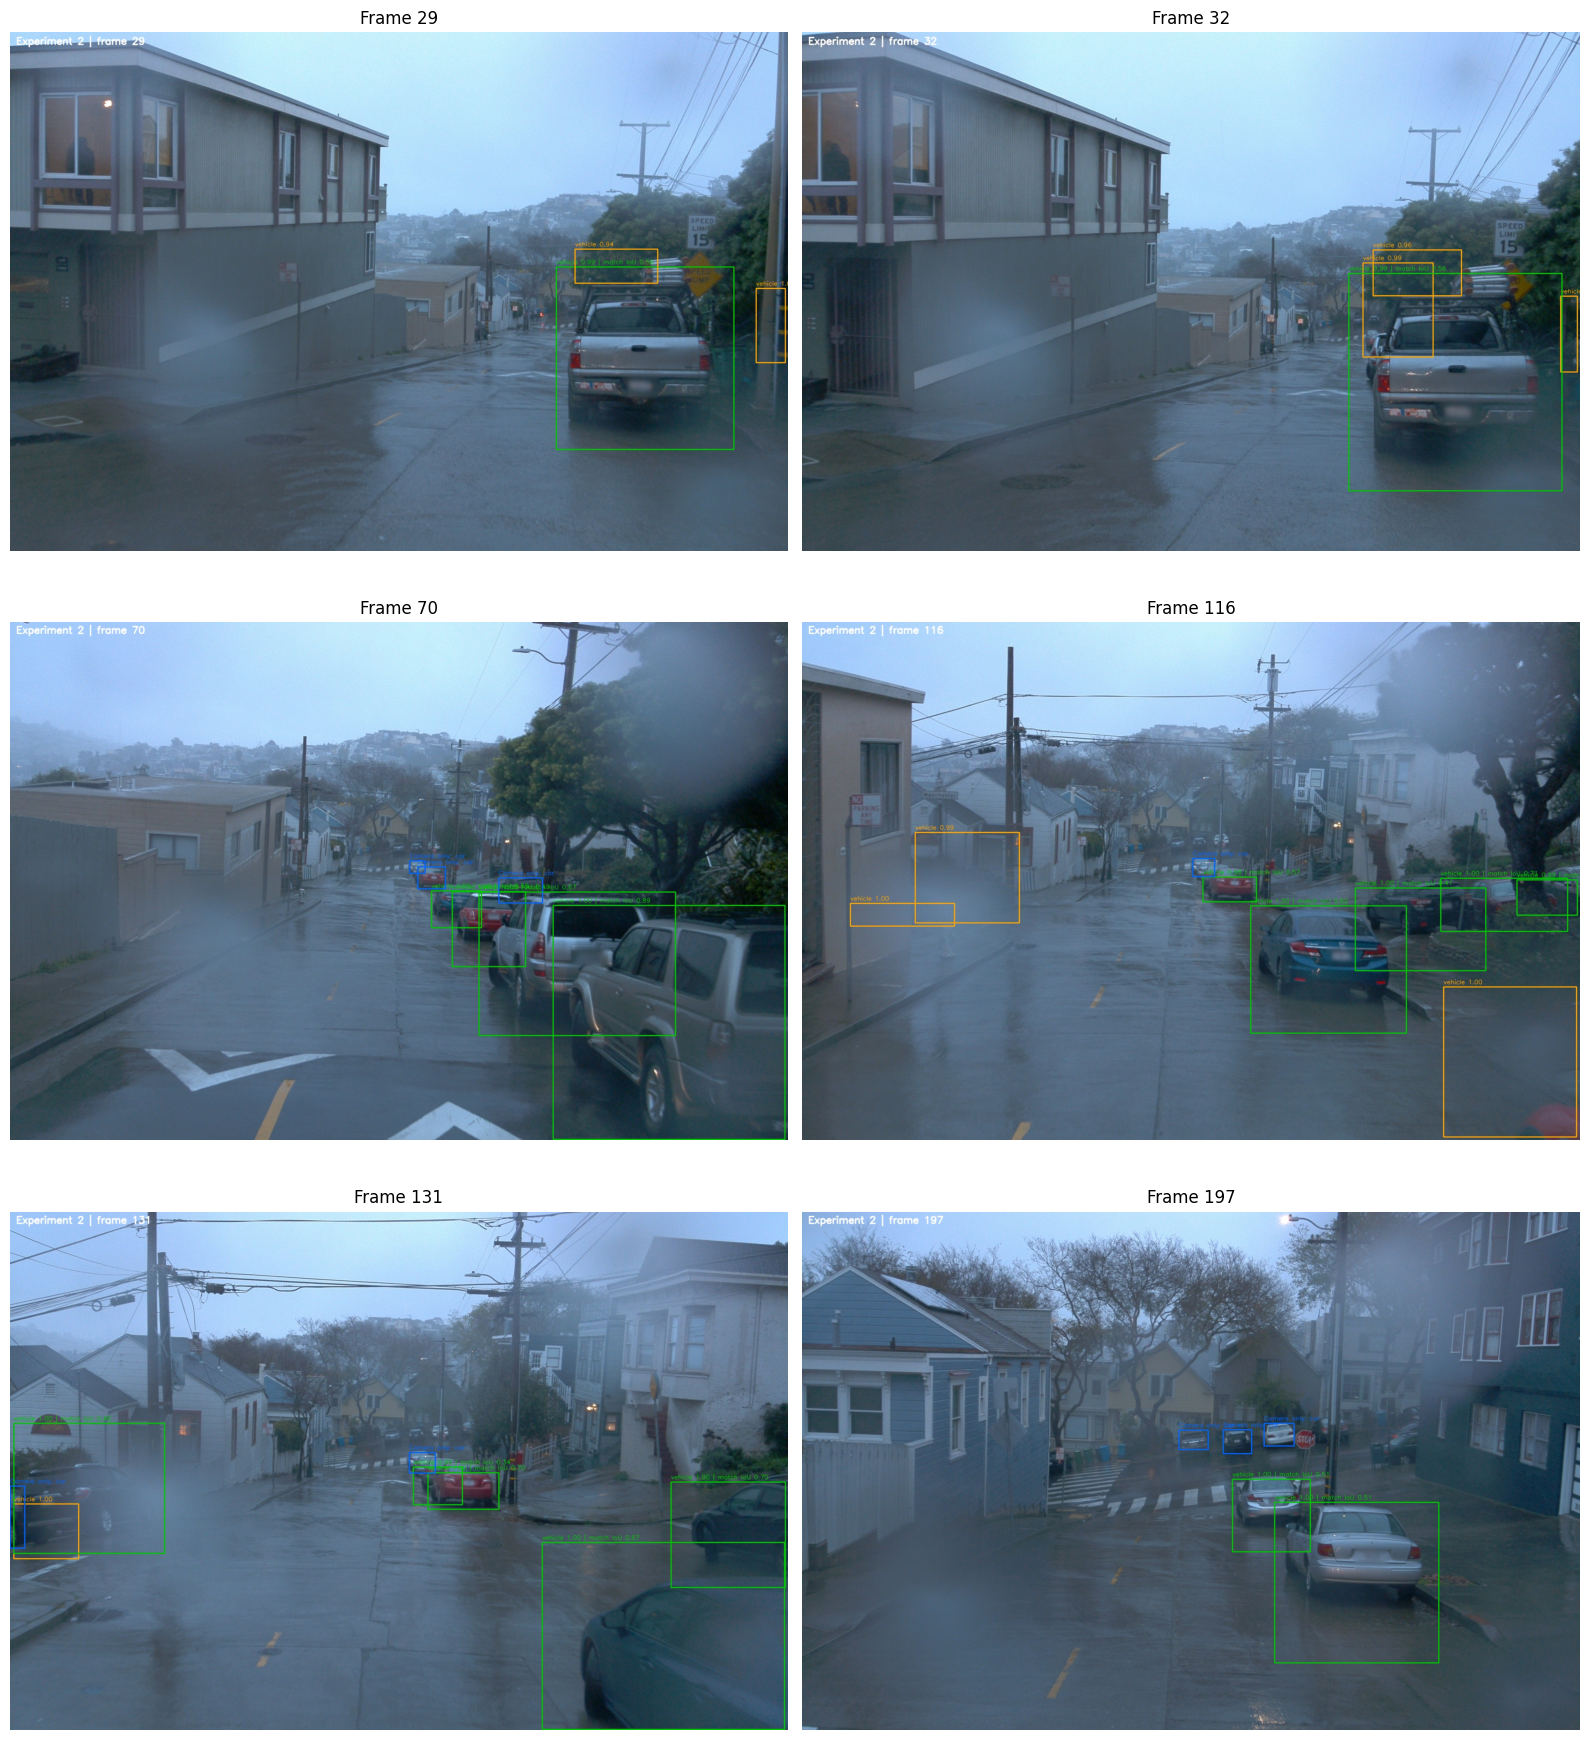

In [ ]:
# Displays six selected frame visualizations.
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

results_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results"
)

frame_ids = [29, 32, 70, 116, 131, 197]

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

for ax, frame_id in zip(axes.flat, frame_ids):
    image_path = results_dir / f"frame_{frame_id:03d}.jpg"

    if image_path.exists():
        ax.imshow(Image.open(image_path))
        ax.set_title(f"Frame {frame_id}")
    else:
        ax.set_title(f"Frame {frame_id}: image not found")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Prints the CSV columns and first ten rows.
import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results/detections.csv"
)

df = pd.read_csv(csv_path)

print("Columns:")
print(df.columns.tolist())
print("\nFirst 10 rows:")
display(df.head(10))

Columns:
['frame_idx', 'lidar_class', 'lidar_score', 'x', 'y', 'z', 'dx', 'dy', 'dz', 'heading', 'projected_camera_box', 'matched_camera_labels', 'matched_camera_score', 'match_iou', 'matched']

First 10 rows:


,frame_idx,lidar_class,lidar_score,x,y,z,dx,dy,dz,heading,projected_camera_box,matched_camera_labels,matched_camera_score,match_iou,matched
0,0,vehicle,0.995896,21.057755,-4.656215,2.389218,4.583426,2.198709,0.744294,-1.711622,"[1188.3785363110455, 556.143304327291, 1713.18...",car,0.326485,0.543098,True
1,0,vehicle,0.994255,31.916040,-2.384731,2.837064,6.328757,2.625450,0.979169,-0.141177,"[992.4858804930336, 532.6219082111862, 1201.12...",car,0.620095,0.461429,True
2,0,vehicle,0.986894,19.126093,12.595178,0.542824,5.399682,2.304419,1.244102,-1.718556,NaN,NaN,NaN,NaN,False
3,1,vehicle,0.996039,18.715397,12.605136,0.548918,5.685061,2.374657,1.275402,-1.664593,NaN,NaN,NaN,NaN,False
4,1,vehicle,0.995526,31.280149,-2.639254,2.787328,5.937348,2.511117,1.035591,-0.195893,"[1007.4473483518782, 533.3363194168844, 1228.6...",car,0.605597,0.452366,True
5,1,vehicle,0.992000,20.482389,-4.831887,2.351856,4.734337,2.219947,0.771141,-1.762632,"[1201.3585735203892, 557.3383687323934, 1763.6...",car,0.391144,0.516413,True
6,2,vehicle,0.991450,30.684130,-2.967327,2.770541,6.044569,2.453257,1.012585,-0.225181,"[1029.6036783353034, 533.880653005401, 1259.06...",car,0.488602,0.438164,True
7,2,vehicle,0.989399,19.843649,-4.975283,2.367208,4.509842,2.189287,0.793635,-1.770867,"[1239.7017200287282, 552.4424795105558, 1795.9...",car,0.394375,0.510087,True
8,2,vehicle,0.988922,18.139862,12.447242,0.557285,5.607585,2.349685,1.248712,-1.696487,NaN,NaN,NaN,NaN,False
9,2,vehicle,0.664569,26.119381,15.247197,1.497861,4.142767,1.908953,0.699249,1.236499,NaN,NaN,NaN,NaN,False


In [ ]:
# Summarizes projected, matched and unmatched detections, including a cross-tabulation and per-frame statistics.
import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "project/experiments/experiment_2_results/detections.csv"
)
df = pd.read_csv(csv_path)

has_projection = df["projected_camera_box"].notna()
matched = df["matched"].astype(str).str.lower().eq("true")

print("DETECTION PIPELINE SUMMARY")
print(f"Total LiDAR detections: {len(df)}")
print(f"Successfully projected: {has_projection.sum()} "
      f"({has_projection.mean():.1%})")
print(f"Matched: {matched.sum()} ({matched.mean():.1%} of all LiDAR detections)")
print(f"Projected but unmatched: {(has_projection & ~matched).sum()}")
print(f"Not projected: {(~has_projection).sum()}")

print("\nPROJECTED DETECTIONS: MATCHED VS UNMATCHED")
print(pd.crosstab(
    has_projection.map({True: "Projected", False: "Not projected"}),
    matched.map({True: "Matched", False: "Unmatched"})
))

print("\nPER-FRAME SUMMARY")
per_frame = df.groupby("frame_idx").agg(
    lidar_detections=("frame_idx", "size"),
    projected=("projected_camera_box",
               lambda s: s.notna().sum()),
    matched=("matched", lambda s: s.astype(str).str.lower().eq("true").sum())
)
per_frame["projected_unmatched"] = (
    per_frame["projected"] - per_frame["matched"]
)
display(per_frame.describe().round(2))


DETECTION PIPELINE SUMMARY
Total LiDAR detections: 1095
Successfully projected: 742 (67.8%)
Matched: 545 (49.8% of all LiDAR detections)
Projected but unmatched: 197
Not projected: 353

PROJECTED DETECTIONS: MATCHED VS UNMATCHED
matched               Matched  Unmatched
projected_camera_box                    
Not projected               0        353
Projected                 545        197

PER-FRAME SUMMARY


,lidar_detections,projected,matched,projected_unmatched
count,198.00,198.00,198.00,198.00
mean,5.53,3.75,2.75,0.99
std,1.77,1.34,0.90,1.05
min,2.00,2.00,1.00,0.00
25%,4.00,3.00,2.00,0.00
50%,5.00,3.00,3.00,1.00
75%,6.00,4.00,3.00,2.00
max,10.00,8.00,5.00,5.00
